In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os, sys

class HidePrinting:
    def __enter__(self):
        self._original_stdout = sys.stdout
        sys.stdout = open(os.devnull, 'w')

    def __exit__(self, exc_type, exc_val, exc_tb):
        sys.stdout.close()
        sys.stdout = self._original_stdout

In [3]:
import os
import sys

sys.path.append('Code')
os.environ["STAR_ROUTINES_PATH"] = os.getcwd() + '/Code/'

from star_routines import *

In [4]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, mass=0.0, phi0=0.1)
solver.shoot_for_omega(omega_range=[2,4])

Omega found by shooting 2.9804


In [5]:
solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, mass=0.0, phi0=1.0)
solver.shoot_for_omega(omega_range=[7,9])

Omega found by shooting 2.1148


In [6]:
solver = Bose_Star_Solver(d=2, l=1.0, kappa=1.0, mass=0.0, phi0=0.5)
solver.shoot_for_omega(omega_range=[1.9,5])

Omega found by shooting 1.4258


In [7]:
solver = Bose_Star_Solver(d=2, l=1.0, kappa=1.0, mass=0.0, phi0=0.5)
solver.shoot_for_omega(omega_range=[5,7])

Omega found by shooting 2.0744


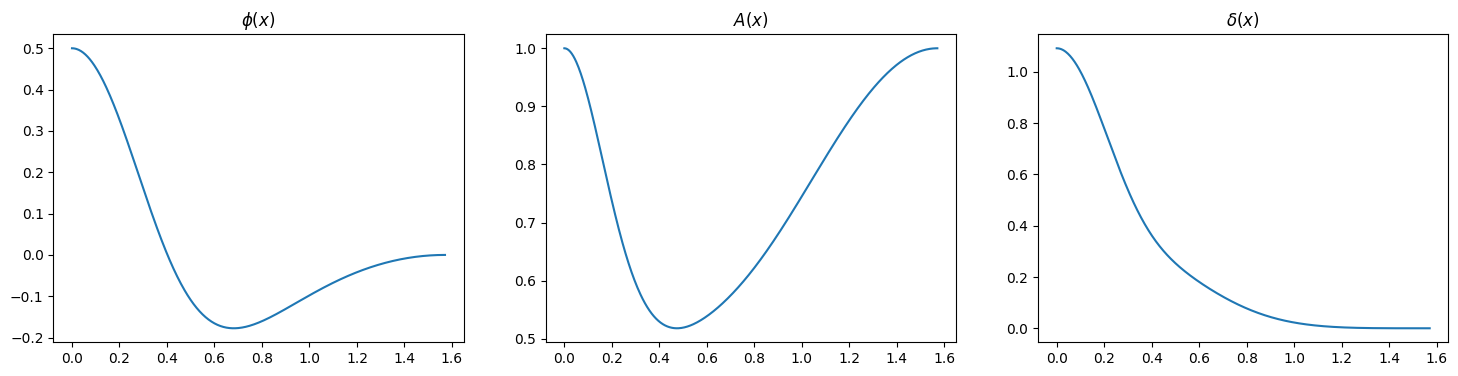

In [8]:
%matplotlib inline
solver.get_star_profile()
solver.plot_star_profile()

## Investigating a family of solutions

In [9]:
phi0_range = np.linspace(0.01, 0.5)
omegas = []

with HidePrinting():
    for phi0 in phi0_range:
        solver = Bose_Star_Solver(d=3, l=1.0, kappa=1.0, mass=0.0, phi0=phi0)
        solver.shoot_for_omega(omega_range=[2,4])
        omegas.append(solver.omega)

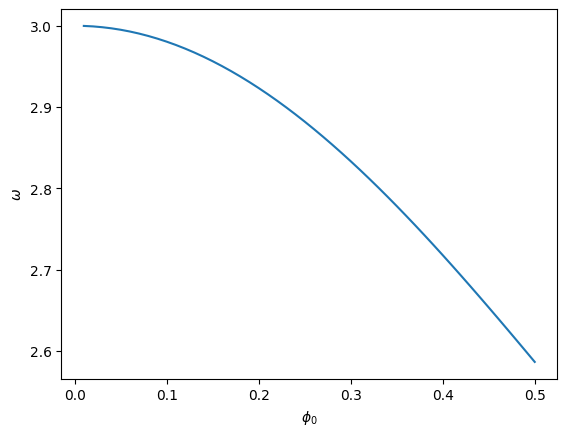

In [10]:
plt.plot(phi0_range, omegas)
plt.xlabel('$\\phi_0$')
plt.ylabel('$\\omega$')
plt.show()

## Comparing with exact solution in the absence of gravity

In [11]:
from scipy.special import jacobi

The exact solutions for the scalar field in the absence of gravity is given by the formula
$$
\phi_j(x) = C (\cos x)^{(d + \sqrt{d^2 + 4 l^2 m^2})/2} P^{d/2 - 1, \sqrt{d^2 + 4 l^2 m^2}/2}_j(\cos 2x),
$$
and have the frequency
$$
\phi_0 = \frac{1}{2}(d + \sqrt{d^2 + 4 l^2 m^2}) + 2j.
$$

In [12]:
class Phi_Exact:
    def __init__(self, d, l, m):
        self.d_2 = d/2.0
        self.l = l
        self.m = m
        self.alpha = self.d_2 - 1.0
        self.beta = 0.5*np.sqrt(d**2 + (2*m*l)**2)
    def omega(self, j):
        return self.d_2 + self.beta + 2*j
    def __call__(self, j, xrange):
        jacobi_j = jacobi(j, self.alpha, self.beta)
        norm = jacobi_j(1.0)
        return np.cos(xrange)**(self.d_2 + self.beta)*jacobi_j(np.cos(2*xrange))/norm

### $d = 2$

Omega found by shooting 2.1180
Exact omega 2.118033988749895
Maximal difference between numeric and exact solutions 2.93e-07


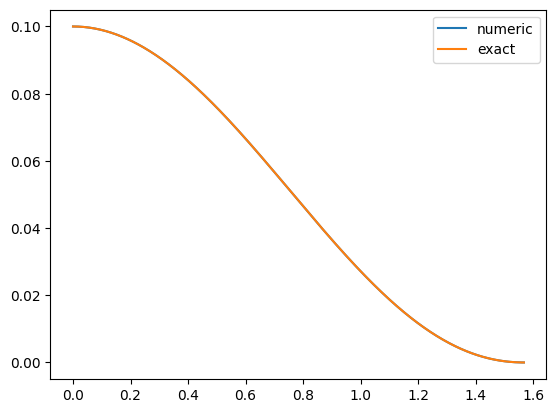

In [13]:
d = 2
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, mass=m, phi0=0.1)
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[2, 3])
print("Exact omega", phi_exact.omega(0))

solver.get_star_profile()
phi_func = 0.1*phi_exact(0, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

Omega found by shooting 4.1180
Exact omega 4.118033988749895
Maximal difference between numeric and exact solutions 5.44e-06


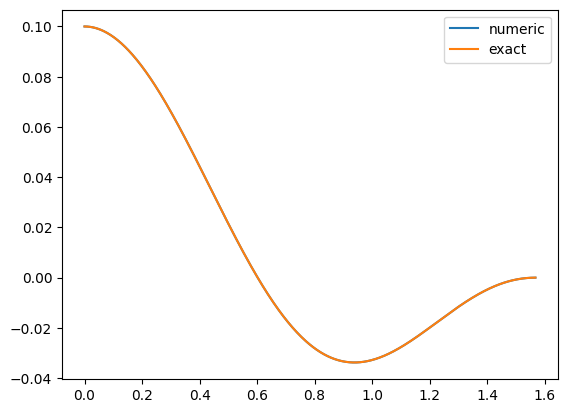

In [14]:
d = 2
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, mass=m, phi0=0.1, xrange=[0.001, 1.45])
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[4, 5])
print("Exact omega", phi_exact.omega(1))

solver.get_star_profile()
phi_func = 0.1*phi_exact(1, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

### $d = 3$

Omega found by shooting 3.0811
Exact omega 3.08113883008419
Maximal difference between numeric and exact solutions 4.18e-07


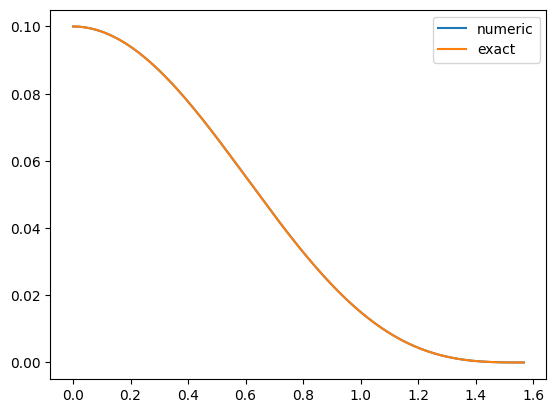

In [15]:
d = 3
l = 1
m = 0.5
solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, mass=m, phi0=0.1)
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[1,4])
print("Exact omega", phi_exact.omega(0))

solver.get_star_profile()
phi_func = 0.1*phi_exact(0, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

Omega found by shooting 5.0811
Exact omega 5.08113883008419
Maximal difference between numeric and exact solutions 2.28e-07


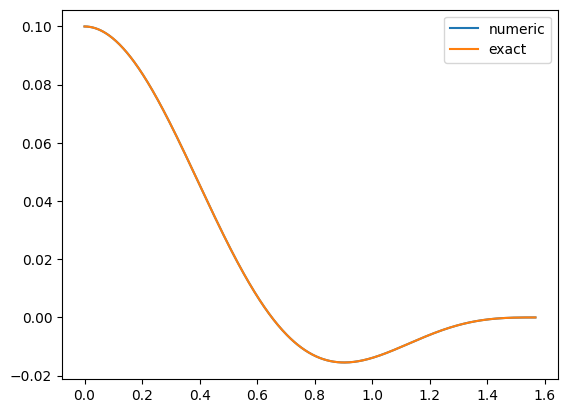

In [16]:
d = 3
l = 1
m = 0.5

solver = Bose_Star_Solver(d=d, l=l, kappa=0.0, mass=m, phi0=0.1, xrange=[0.001, 1.45])
phi_exact = Phi_Exact(d, l, m)

solver.shoot_for_omega(omega_range=[4,6])
print("Exact omega", phi_exact.omega(1))

solver.get_star_profile()
phi_func = 0.1*phi_exact(1, solver.coords[:-1])
print("Maximal difference between numeric and exact solutions %.2e" % np.abs(phi_func - solver.fields[:-1,2]).max())

plt.plot(solver.coords[:-1], solver.fields[:-1,2], label='numeric')
plt.plot(solver.coords[:-1], phi_func, label='exact')
plt.legend()
plt.show()

# Old

## CSV reader

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

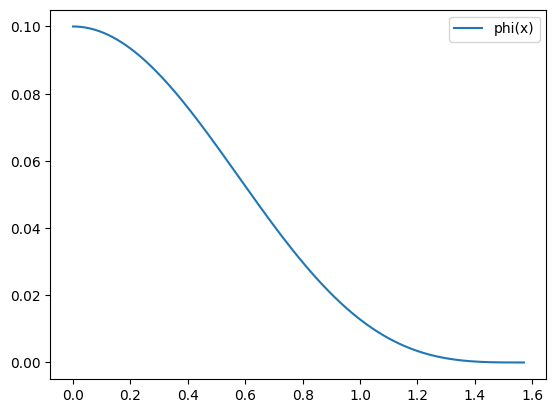

In [11]:
%matplotlib inline
df = pd.read_csv("Code/Data/solution.dat")
# plt.xlim(0,np.pi/2)
# plt.plot(df['x'], df['y0'], label='A(x)')
# plt.plot(df['x'], df['y1'], label='delta(x)')
plt.plot(df['x'], df['y2'], label='phi(x)')
# plt.plot(df['x'], 0.1*(np.cos(df['x']))**3.302, label='exact')
plt.legend()
plt.show()

## Cubic Solver

Solves equation $a x^3 + b x = c$

In [12]:
def solve_cubic(a,b,c, e=1.0e-4):
    if(np.abs(a) > e):
        det = np.sqrt((c/(2.0*a))**2 + (b/(3.0*a))**3)
        return (det + c/(2.0*a))**(1/3) - (det - c/(2.0*a))**(1/3)
    else:
        return c/b*(1.0 - a*c*c/(b*b*b) + 3*a*a*(c**4)/(b**6))

In [13]:
a0 = 3.0e-4
b0 = 4.0
c0 = 3.0
y = solve_cubic(a0, b0, c0)

print(y)
print(a0*(y**3) + b0*y - c0)

0.7499683633788408
-8.881784197001252e-16


In [14]:
a0 = 2.0
b0 = 4.0
c0 = 3.0
y = solve_cubic(a0, b0, c0)

print(y)
print(a0*(y**3) + b0*y - c0)

0.6268452758262435
-4.440892098500626e-16
